In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv("../data/Dataset.csv")
print(df.head())

  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dr

In [3]:
print(df.shape)

(8790, 10)


In [4]:
print(df.columns.tolist())

['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [5]:
print("Earliest release_year")
print(df['release_year'].min())
print("Latest release_year")
print(df['release_year'].max())


Earliest release_year
1925
Latest release_year
2021


In [6]:
print("Missing Release_year")
print(df['release_year'].isnull().sum())
print("Title per year")
print(df['release_year'].value_counts().sort_index().head(10))

Missing Release_year
0
Title per year
release_year
1925    1
1942    2
1943    3
1944    3
1945    4
1946    2
1947    1
1954    2
1955    3
1956    2
Name: count, dtype: int64


In [7]:
year_titles=(df.dropna(subset=['release_year'])
.groupby('release_year')
.size()
.sort_index()
)
year_titles.index=year_titles.index.astype(int)
year_titles.name='title_count'

print(year_titles.head())
print("Total years:", len(year_titles))

release_year
1925    1
1942    2
1943    3
1944    3
1945    4
Name: title_count, dtype: int64
Total years: 74


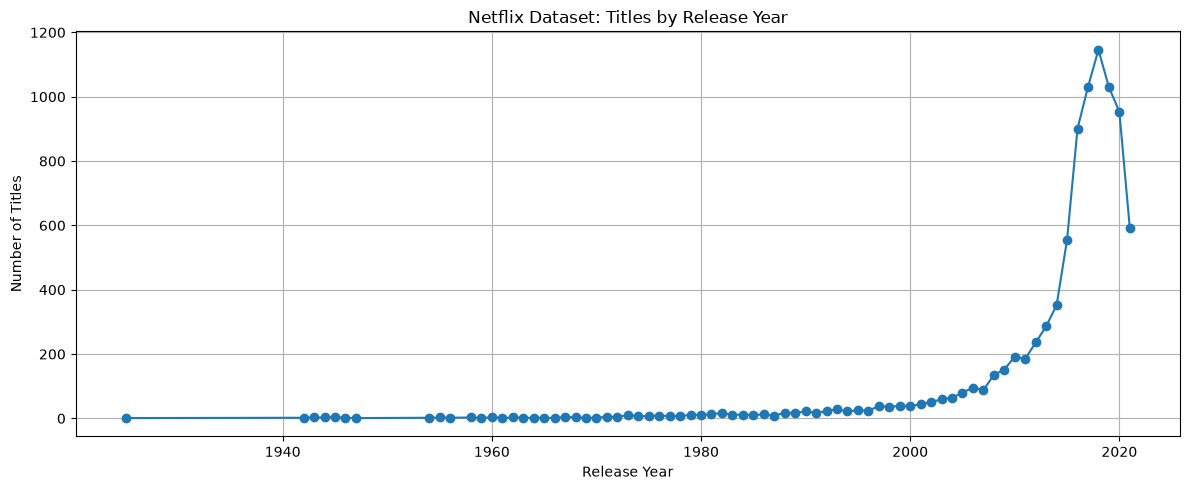

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(year_titles.index, year_titles.values, marker="o")
plt.title("Netflix Dataset: Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

Minimum Release Year:1925
Average movies released:1941-1959
Maxmimum Movies released:1960-2021

In [9]:
all_years=range(int(year_titles.index.min()),int(year_titles.index.max())+1)
yearly_titles=year_titles.reindex(all_years,fill_value=0)
yearly_titles.index.name='release_year'
print(yearly_titles.head())
print("Total Yearly Observation",len(yearly_titles))

release_year
1925    1
1926    0
1927    0
1928    0
1929    0
Name: title_count, dtype: int64
Total Yearly Observation 97


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error

data=yearly_titles.reset_index()
X=data[['release_year']]
y=data[['title_count']]
split_index=int(len(data)*0.8)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
print("Training years:", X_train["release_year"].min(),
      "-", X_train["release_year"].max())
print("Testing years:", X_test["release_year"].min(),
      "-", X_test["release_year"].max())
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_pred = np.maximum(y_pred, 0)



Training years: 1925 - 2001
Testing years: 2002 - 2021
Model trained successfully!


In [12]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

Mean Absolute Error (MAE): 381.91
Root Mean Squared Error (RMSE): 536.65


In [ ]:
# Generate future years
future_years = pd.DataFrame({
    "release_year": range(
        int(data["release_year"].max()) + 1,
        int(data["release_year"].max()) + 6
    )
})
future_predictions = model.predict(future_years[["release_year"]])
future_predictions = np.asarray(future_predictions).reshape(-1)
future_predictions = np.maximum(future_predictions, 0)
future_forecast = pd.DataFrame({
    "release_year": future_years["release_year"].to_numpy(),
    "predicted_title_count": np.round(future_predictions).astype(int)
})
print(future_forecast)

   release_year  predicted_title_count
0          2022                     31
1          2023                     32
2          2024                     32
3          2025                     33
4          2026                     33


In [15]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))


Mean Absolute Error (MAE): 381.91
Root Mean Squared Error (RMSE): 536.65


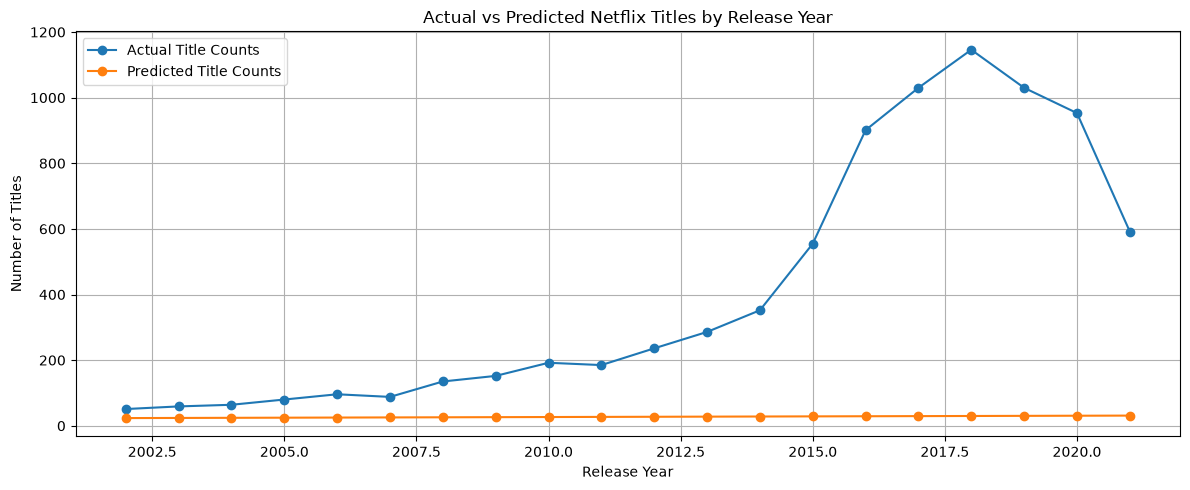

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(X_test["release_year"],y_test, marker="o",label="Actual Title Counts")
plt.plot( X_test["release_year"], y_pred, marker="o", label="Predicted Title Counts")
plt.title("Actual vs Predicted Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_pred = np.maximum(rf_pred, 0)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))

print("Linear Regression MAE:", round(mae, 2))
print("Linear Regression RMSE:", round(rmse, 2))


C:\Users\Designer\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random Forest MAE: 367.2
Random Forest RMSE: 527.71

Linear Regression MAE: 381.91
Linear Regression RMSE: 536.65


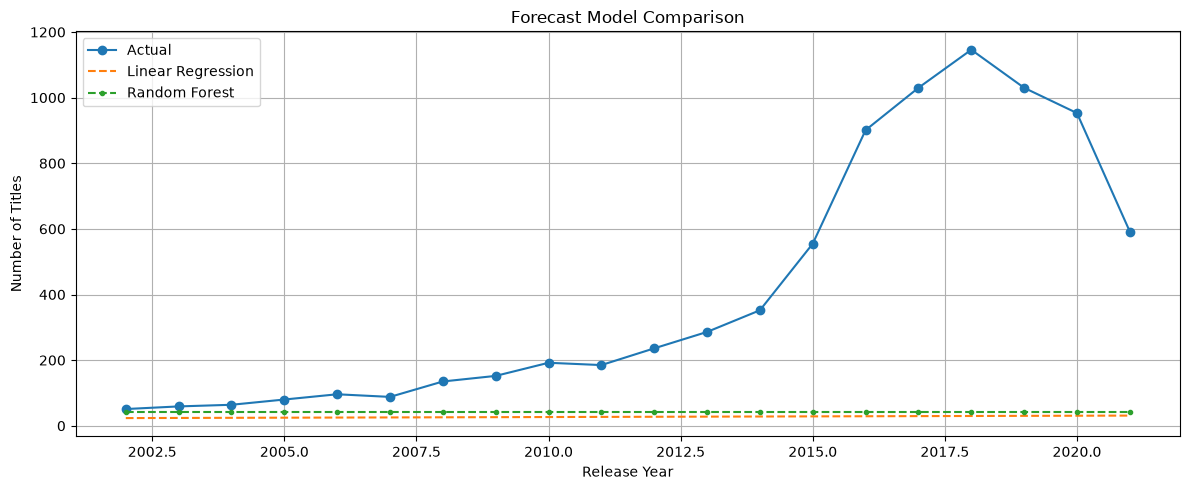

In [ ]:

plt.figure(figsize=(12, 5))
plt.plot( X_test["release_year"], y_test, marker="o", label="Actual")
plt.plot( X_test["release_year"], y_pred, linestyle="--", label="Linear Regression")
plt.plot(  X_test["release_year"], rf_pred,linestyle="--", marker=".", label="Random Forest")
plt.title("Forecast Model Comparison")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Conclusion

In this project, I developed a Netflix content trend forecasting model using historical title release years. I analyzed yearly title counts, visualized historical trends, and trained two regression models: Linear Regression and Random Forest Regressor.
The models were evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Linear Regression achieved an MAE of 381.91 and RMSE of 536.65, while Random Forest achieved an MAE of 367.20 and RMSE of 527.71. Random Forest performed slightly better on the test dataset, although both models showed substantial prediction errors.
This project helped me practice time-based data preparation, trend visualization, regression modeling, forecasting, and model evaluation. The results also demonstrate the limitations of simple models when historical trends change sharply. Future improvements could include testing time-series forecasting methods and evaluating forecasts against more recent, reliable data.